# 03_perturb: the Tbx5 knockout

`perturb.py` rolls a knockout forward from E8.0 to E9.5 on clades whose E8.0 progenitor
expresses Tbx5. Three modes, same clades, same topology, 8 draws each:

- **control** copies every node's own state and makes no model call, so it reproduces the observed tree
- **sham** resamples exactly the lineages the knockout resamples but moves nothing: pure rollout drift
- **knockout** projects every Tbx5-expressing state onto its nearest non-expressing cell

The sham is the comparison that matters. control -> sham is what the forward rollout does on its
own; sham -> knockout is what Tbx5 does.

```bash
python perturb.py run_name=cand1 mode=control
python perturb.py run_name=cand1 mode=sham
python perturb.py run_name=cand1 mode=knockout
python perturb.py run_name=cand1 mode=knockout source=counts
```

In [1]:
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from hydra.utils import instantiate
from omegaconf import OmegaConf
from li.plot.tree import card, GREY
from li.plot.umap import atlas, path
from li.perturb.project import target_bank, project
from matplotlib.patches import Patch

RUN, GENE, CUTOFF, K = "../runs/cand1", "Tbx5", 100.0, 8
POST = ["atria", "inflow tract", "atrioventricular canal", "left ventricle"]
ANT = ["outflow tract", "right ventricle", "second heart field (anterior)"]

cfg = OmegaConf.load("../config/data/mouse.yaml")
DATA = OmegaConf.to_container(cfg, resolve=True)["root"] + "/embryos"
data = instantiate(cfg, device="cuda", _convert_="all")
slab = data.labels["subtype"]

# subtype colours, not cell_type: cell_type merges atria / inflow / outflow / right ventricle
# into one "second heart field" and would hide the whole phenotype
ti = pd.read_csv(f"{DATA}/final_type_info_v2_lower.csv")
SCOL = dict(zip(ti.cell_subtype, ti.subtype_color))

res = {m: pd.read_parquet(f"{RUN}/perturb_{GENE}_{m}.parquet")
       for m in ("control", "sham", "knockout")}
for v in res.values():
    v["ct"] = slab.reindex(v.cell).values
leaf = {m: v[np.abs(v.time - 9.5) < 0.26] for m, v in res.items()}
base = leaf["control"][leaf["control"]["sample"] == 0].set_index(["tree", "node"])["ct"]
clades = pd.read_csv(f"{RUN}/perturb_clades_{GENE}.csv")
print({m: len(v) // K for m, v in leaf.items()}, "readout leaves per draw")
clades

{'control': 1331, 'sham': 1331, 'knockout': 1331} readout leaves per draw


,tree,root,node,time,n_leaves,on,forelimb,heart_post,hindlimb,heart_ant,kind
0,E9.5-R1-C1,103728,AAVyt4ex,8.014291,196,0.750,124,11,0,0,forelimb
1,E9.5-R3-C3,8643,xSqBRZP2,7.904827,205,0.875,63,15,0,0,forelimb
2,E9.5-R2-C2,6104,jtxa79hr,8.121141,106,0.875,61,0,0,0,forelimb
3,E9.5-R3-C2,15778,h7UlSC6v,7.815939,219,0.625,52,0,1,0,forelimb
4,E9.5-R1-C2,107109,LVQ45yDs,8.218777,133,0.625,49,0,0,0,forelimb
5,E9.5-R1-C1,73275,0VXqknQt,8.151067,90,1.000,47,0,0,0,forelimb
6,E9.5-R3-C2,7290,nfiV3USw,7.762186,74,1.000,0,43,0,18,heart_post
7,E9.5-R2-C1,119246,7b3tAiDQ,7.773704,90,1.000,0,36,0,0,heart_post
8,E9.5-R1-C1,70749,rtEz2mZR,7.884385,65,1.000,0,32,0,0,heart_post
9,E9.5-R2-C2,137293,mVLoHLpR,7.819859,61,0.875,0,31,0,0,heart_post


## 1. the generated trees

Each clade is drawn three times on the same topology. An edge takes its child's modal subtype
over the 8 draws and fades with disagreement; the small squares are one tick per draw, so a row
of mixed colours is a node the model does not agree with itself about. Leaves are the E9.5 readout.

The control is one colour per node because it never calls the model. The sham shows what the
forward rollout alone does to the same lineages.

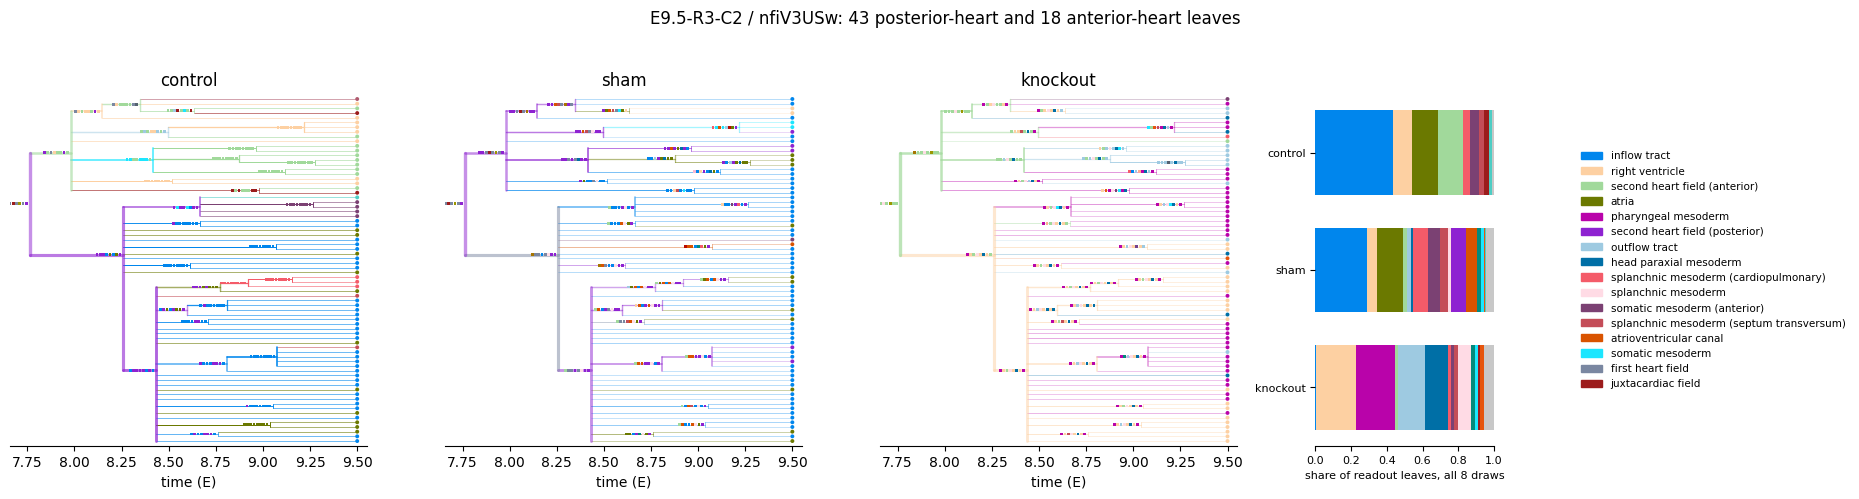

In [2]:
MODES = ("control", "sham", "knockout")

def labmat(mode, tree, r, col="ct"):
    "clade nodes x draws, leaves included (li.eval.nodes.clade overwrites leaves with observed)"
    nd = np.arange(r, tree.end[r])
    out = np.full((len(nd), K), None, dtype=object)
    c = res[mode]
    c = c[c.tree == tree.name]
    pos = pd.Index(tree.nodes[nd]).get_indexer(c.node)
    k = pos >= 0
    out[pos[k], c["sample"].values[k]] = c[col].values[k]
    return out

def leaf_modal(tree, r, lab):
    "card draws a leaf from draw 0; show its modal subtype over all draws instead"
    out = lab.copy()
    for i in np.flatnonzero(tree.leaf[np.arange(r, tree.end[r])]):
        v = pd.Series(out[i]).dropna().value_counts()
        if len(v):
            out[i, 0] = v.index[0]
    return out

def compbar(ax, tree, r, labs, n=18):
    "readout composition over every draw, so it stays readable however many leaves there are"
    lf = tree.leaf[np.arange(r, tree.end[r])]
    keep = pd.Series(np.concatenate([l[lf].ravel() for l in labs])).dropna().value_counts().index[:n]
    for i, l in enumerate(labs):
        v = pd.Series(l[lf].ravel()).dropna().value_counts(normalize=True)
        left = 0.0
        for sname in keep:
            w = v.get(sname, 0.0)
            if w:
                ax.barh(i, w, left=left, color=SCOL.get(sname, GREY), height=0.72)
            left += w
        if left < 1:
            ax.barh(i, 1 - left, left=left, color=GREY, height=0.72)
    ax.set_yticks(range(len(labs)))
    ax.set_yticklabels(MODES)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel(f"share of readout leaves, all {K} draws", fontsize=8)
    ax.tick_params(labelsize=8)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)

def legend_top(ax, labs, n=16):
    v = pd.Series(np.concatenate([np.ravel(l) for l in labs])).dropna().value_counts().head(n)
    ax.legend(handles=[Patch(color=SCOL.get(sname, GREY), label=sname) for sname in v.index],
              frameon=False, loc="center left", fontsize=7.5)
    ax.axis("off")

def show(row, title):
    tree, r = data.trees[row.tree], int(row.root)
    raw = [labmat(m, tree, r) for m in MODES]
    fig, ax = plt.subplots(1, 5, figsize=(19, 4.8),
                           gridspec_kw={"width_ratios": [1, 1, 1, 0.5, 0.62]})
    for a, m, l in zip(ax, MODES, raw):
        card(a, tree, r, leaf_modal(tree, r, l), SCOL)
        a.set_title(m)
    compbar(ax[3], tree, r, raw)
    legend_top(ax[4], raw)
    fig.suptitle(title, y=1.03)
    fig.tight_layout()
    plt.show()

h = clades[clades.kind == "heart_post"].iloc[0]
show(h, f"{h.tree} / {h.node}: {h.heart_post} posterior-heart and {h.heart_ant} anterior-heart leaves")

The posterior pole (inflow tract, atria, left ventricle) fills the control readout and is gone under
knockout, replaced by right ventricle and head / pharyngeal mesoderm. The sham keeps it, so that
shift is the gene and not the rollout. Leaf dots are the modal subtype over the 8 draws; the bar is
every draw. Note how speckled the sham and knockout ticks are, which is the disagreement quantified
in section 4.

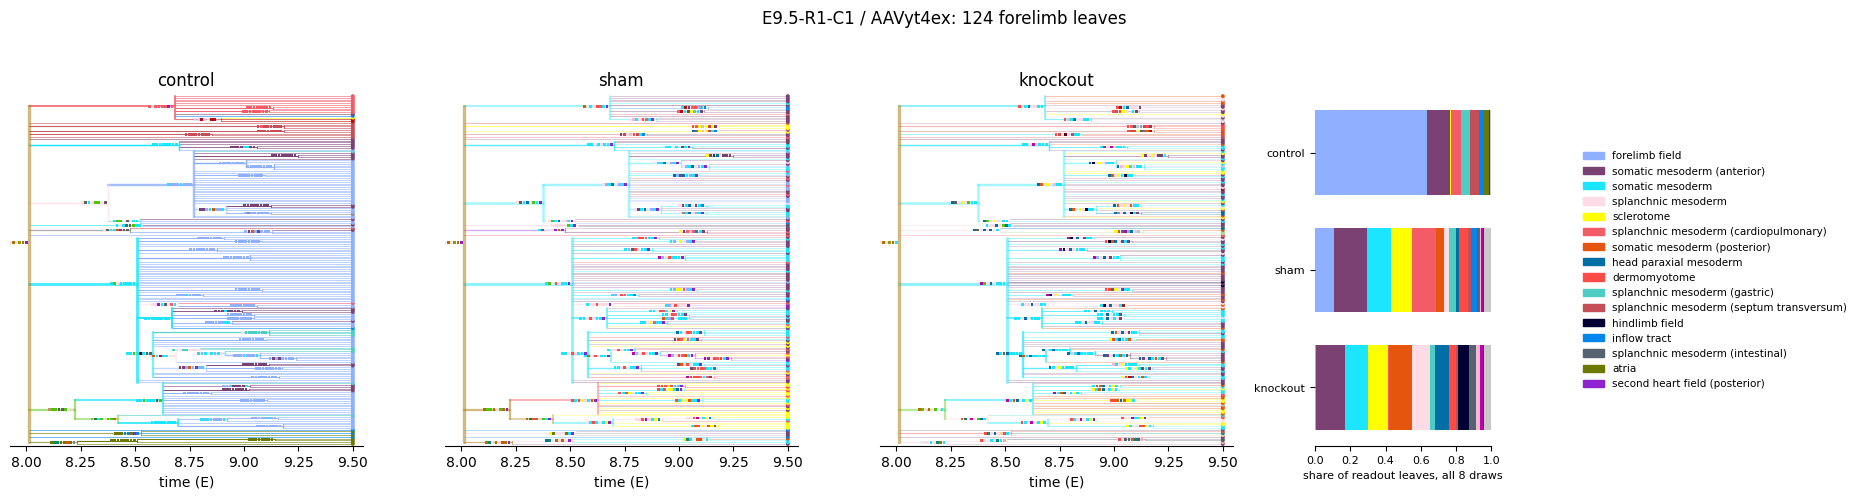

In [3]:
f = clades[clades.kind == "forelimb"].iloc[0]
show(f, f"{f.tree} / {f.node}: {f.forelimb} forelimb leaves")

## 2. the same clade on the atlas

Each draw's ancestors joined parent to child, coloured by node time, over a grey atlas; leaves in
their subtype colour. All three panels share one frame. The control sits in a tight pocket of the
atlas; the knockout's paths sprawl across it, which is the same draw-to-draw disagreement seen in
the cards.

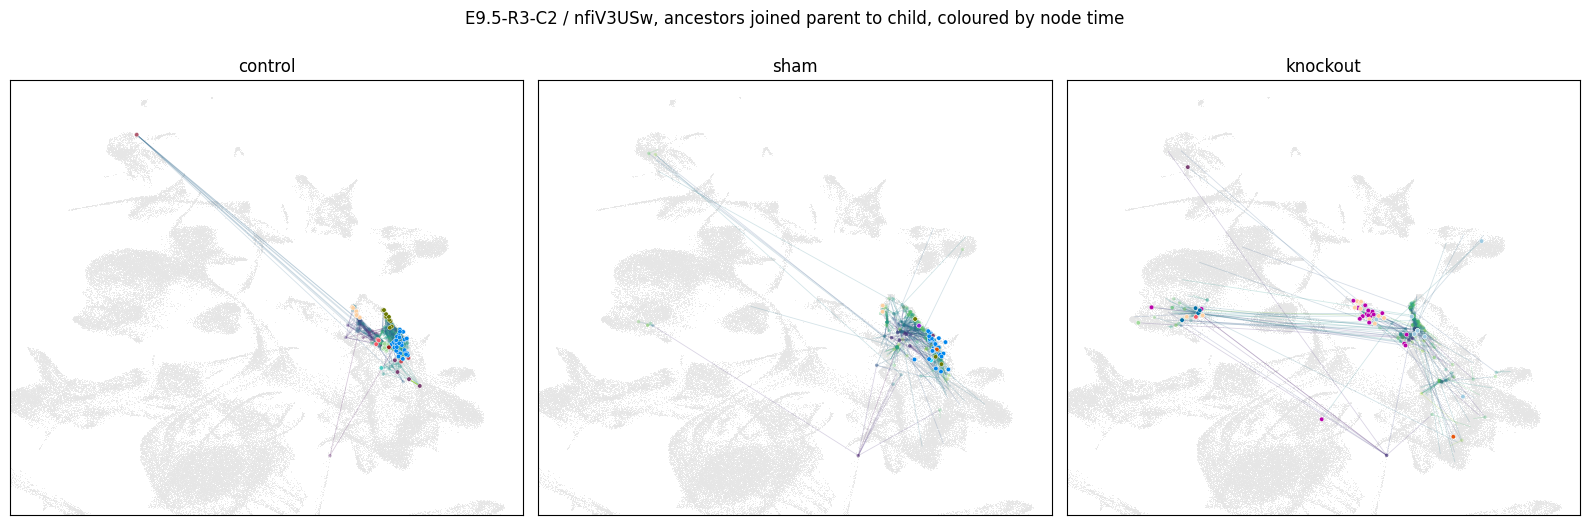

In [4]:
tree, r = data.trees[h.tree], int(h.root)
lf = tree.leaf[np.arange(r, tree.end[r])]
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))
for a, m in zip(ax, MODES):
    atlas(a, data.umap, n=120_000)
    path(a, data.umap, tree, r, labmat(m, tree, r, col="cell"), SCOL,
         leaf_modal(tree, r, labmat(m, tree, r))[lf, 0])
    a.set_title(m)
xl = [a.get_xlim() for a in ax]
yl = [a.get_ylim() for a in ax]
for a in ax:  # one frame for all three, else the knockout only looks wider because it is zoomed out
    a.set_xlim(min(x[0] for x in xl), max(x[1] for x in xl))
    a.set_ylim(min(y[0] for y in yl), max(y[1] for y in yl))
fig.suptitle(f"{h.tree} / {h.node}, ancestors joined parent to child, coloured by node time", y=1.0)
fig.tight_layout()
plt.show()

## 3. composition of the readout, per draw

In [5]:
rows = []
for m, x in leaf.items():
    for g, q in (("forelimb", x.ct == "forelimb field"), ("hindlimb", x.ct == "hindlimb field"),
                 ("heart_post", x.ct.isin(POST)), ("heart_ant", x.ct.isin(ANT))):
        c = x[q].groupby("sample").size().reindex(range(K), fill_value=0)
        rows.append((m, g, c.mean(), c.std()))
comp = pd.DataFrame(rows, columns=["mode", "set", "mean", "sd"]).pivot(index="set", columns="mode")
comp.reindex(["forelimb", "hindlimb", "heart_post", "heart_ant"]).round(1)

mean                      sd               
mode       control knockout   sham control knockout  sham
set                                                      
forelimb     398.0      3.0   63.2     0.0      2.3  39.8
hindlimb       1.8     42.9    1.8     0.7     26.1   1.5
heart_post   224.2     13.0  176.8     0.5      9.3  39.7
heart_ant     19.0    118.4   12.2     0.0     74.1  13.6

## 4. how much of that is the rollout rather than the gene

The sham already moves most leaf identities, and the modal subtype wins barely a third of the
eight draws. The backward coupling's agreement is 0.80 for comparison. A single draw of the
forward rollout carries very little, and the published screen took one.

In [6]:
for m in ("sham", "knockout"):
    x = leaf[m].copy()
    x["ctl"] = base.reindex(pd.MultiIndex.from_arrays([x.tree, x.node])).values
    w = x.pivot_table(index=["tree", "node"], columns="sample", values="ct", aggfunc="first")
    ag = w.apply(lambda r: r.value_counts().iloc[0] / r.notna().sum(), axis=1)
    print(f"{m:9s} differs from control {(x.ct != x.ctl).mean():6.1%} | "
          f"modal subtype's share of {K} draws {ag.mean():.2f} | "
          f"all {K} agree {(ag == 1).mean():5.1%} | raw state dist {x[x.resampled].dist.mean():.2f}")

sham      differs from control  82.5% | modal subtype's share of 8 draws 0.37 | all 8 agree  0.1% | raw state dist 4.41
knockout  differs from control  91.3% | modal subtype's share of 8 draws 0.36 | all 8 agree  0.1% | raw state dist 4.35


## 5. the Tbx5-specific part: knockout against its matched sham

Both columns carry the same rollout drift, so the difference is the gene.

In [7]:
def contrast(nodes, n=5):
    sel = lambda m: leaf[m][pd.MultiIndex.from_arrays([leaf[m].tree, leaf[m].node]).isin(nodes)]
    t = pd.DataFrame({"sham": sel("sham").ct.value_counts(normalize=True),
                      "knockout": sel("knockout").ct.value_counts(normalize=True)}).fillna(0)
    t["diff"] = t.knockout - t.sham
    return pd.concat([t.nsmallest(n, "diff"), t.nlargest(n, "diff")]).round(3)

print("control forelimb leaves")
display(contrast(set(base[base == "forelimb field"].index)))
print("control posterior-heart leaves")
display(contrast(set(base[base.isin(POST)].index)))

control forelimb leaves


,sham,knockout,diff
ct,,,
forelimb field,0.124,0.005,-0.120
splanchnic mesoderm (cardiopulmonary),0.072,0.007,-0.065
somatic mesoderm,0.158,0.101,-0.057
somatic mesoderm (anterior),0.116,0.098,-0.018
inflow tract,0.012,0.000,-0.012
hindlimb field,0.002,0.081,0.079
splanchnic mesoderm,0.073,0.129,0.056
sclerotome,0.056,0.094,0.038
somatic mesoderm (posterior),0.160,0.191,0.030


control posterior-heart leaves


,sham,knockout,diff
ct,,,
inflow tract,0.226,0.001,-0.226
atria,0.180,0.000,-0.180
splanchnic mesoderm (cardiopulmonary),0.101,0.016,-0.085
second heart field (posterior),0.071,0.000,-0.071
somatic mesoderm (anterior),0.108,0.038,-0.070
right ventricle,0.016,0.215,0.198
head paraxial mesoderm,0.004,0.111,0.107
splanchnic mesoderm,0.014,0.098,0.084
pharyngeal mesoderm,0.005,0.086,0.082


## 6. the model against projection geometry alone

Snap each observed control leaf straight onto its nearest non-Tbx5 cell: one step, no model, no
trajectory. Geometry gives a much sharper answer than the rollout does, so the crisp part of the
prediction lives in the manifold rather than in the model's trajectory.

In [8]:
col = np.load(f"../cache/gene_decoder_{GENE}.npy")
tb = target_bank(data.bank, col <= CUTOFF, "cuda")
a = leaf["control"][leaf["control"]["sample"] == 0].copy()
row = pd.Series(np.arange(len(data.bank.names)), index=data.bank.names)
r_ = torch.as_tensor(row.reindex(a.cell).values, device=data.bank.emb.device)
new, *_ = project(data.bank.emb[r_], a.time.values, data.bank, tb, col, CUTOFF, 1)
a["geo"] = slab.reindex(data.bank.names[new.cpu().numpy()]).values

for name, q in (("forelimb field", a.ct == "forelimb field"), ("posterior heart", a.ct.isin(POST))):
    g = a[q]
    ko = leaf["knockout"][leaf["knockout"].node.isin(set(g.node))]
    t = pd.DataFrame({"geometry_only": g.geo.value_counts(normalize=True),
                      "model_rollout": ko.ct.value_counts(normalize=True)}).fillna(0)
    print(name)
    display(t.nlargest(6, "model_rollout").round(3))

forelimb field


,geometry_only,model_rollout
somatic mesoderm (posterior),0.060,0.191
splanchnic mesoderm,0.000,0.129
somatic mesoderm,0.000,0.101
somatic mesoderm (anterior),0.070,0.098
sclerotome,0.013,0.094
hindlimb field,0.827,0.081


posterior heart


,geometry_only,model_rollout
right ventricle,0.231,0.215
head paraxial mesoderm,0.005,0.111
splanchnic mesoderm,0.009,0.098
pharyngeal mesoderm,0.000,0.086
outflow tract,0.000,0.069
sclerotome,0.005,0.066


## 7. gene-off by decoder or by counts

Tbx5 is detected in only about three quarters of the cells that express it, so a counts-based
gene-off set is largely dropouts of the very cells the knockout is trying to leave, and projecting
onto one of them does nothing. This is why `source=decoder` is the default.

In [9]:
dec, cnt = np.load(f"../cache/gene_decoder_{GENE}.npy"), np.load(f"../cache/gene_counts_{GENE}.npy")
m = data.bank.time == 9.5
t = pd.DataFrame({"ct": slab.reindex(data.bank.names).values[m],
                  "decoder": (dec > CUTOFF)[m], "counts": (cnt > 0)[m]})
g = t.groupby("ct").agg(n=("decoder", "size"), decoder=("decoder", "mean"), counts=("counts", "mean"))
g[g.n >= 500].assign(gap=lambda x: x.decoder - x.counts).nlargest(10, "gap").round(3)

,n,decoder,counts,gap
ct,,,,
epicardium,1933,0.913,0.442,0.470
splanchnic mesoderm (septum transversum),4244,0.627,0.263,0.364
somatic mesoderm (anterior),19548,0.819,0.475,0.343
left ventricle,1348,0.957,0.622,0.335
inflow tract,3261,0.994,0.702,0.293
juxtacardiac field,2204,0.953,0.664,0.289
forelimb field,31704,0.998,0.727,0.272
second heart field (anterior),1803,0.358,0.099,0.259
endocardial cell,2190,0.403,0.162,0.241
